# You can't manage what you can't map: City of Melbourne council energy and water

The City of Melbourne publishes its own electricity, gas and water bills: a table of rows that name an asset ("Garden -
Treasury", "Library - East Melbourne") with a start date, an end date and an amount. The bills are for the financial year
1 July 2013 to 30 June 2014, the newest metered data the council publishes. A third of the assets have no position in the
council's asset register, so the table cannot be put on a map as it is.

The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com) for the 60 assets that use 90% of each
of electricity, gas and water: council property parcels and 2023 building footprints picked from the council's own open
layers, boulevards drawn as lines along the street, and points for sites with no outline. Each shape carries the
council's asset name as its key. The bills were spread over their days in Plotlay and kept to the financial year.

This notebook reads only the files in `../data` and works out every number it shows. It is a method demonstration for
facilities and asset managers with real council data, not a statement about the council's assets today.

In [1]:
import json, warnings
warnings.filterwarnings('ignore', message='No data for colormapping')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data'
pd.set_option('display.width', 160)
INK, RED, ORANGE, MUTED = '#1d4f91', '#cf3b26', '#e07b00', '#5b6573'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

Bills ("Environmental resources consumed"), the asset register ("Assets for environmental reporting"), the 2023 building
footprints, property boundaries and road corridors: City of Melbourne Open Data, licensed under CC BY 4.0. Shapes made in
Plotlay from those layers; nothing comes from OpenStreetMap or from aerial imagery. Full credits are in `NOTICE`.

## Load

`assets.csv` has one row per asset: the register's fields, how its shape was made and its size. `usage_monthly.csv` is
Plotlay's linked data export (one row per asset, measure and day, in `usage_daily.csv`) totalled by month. Electricity
(kWh), gas (MJ) and water (kL) are kept apart: they are never added together.

In [2]:
assets = pd.read_csv(f'{DATA}/assets/assets.csv')
usage = pd.read_csv(f'{DATA}/usage/usage_monthly.csv')
shapes = gpd.read_file(f'{DATA}/geometry/council_assets.geojson')
assert assets.asset_name.is_unique and shapes.key.is_unique
assert set(usage.measure) == {'Electricity', 'Gas', 'Water'}
assert usage.month.min() == '2013-07' and usage.month.max() == '2014-06'
print(len(assets), 'assets,', len(shapes), 'shapes,', usage.asset_name.nunique(), 'assets with bills on the map')
print(usage.groupby(['measure', 'unit']).amount.sum().round(0))

60 assets, 52 shapes, 52 assets with bills on the map
measure      unit
Electricity  kWh      9698626.0
Gas          MJ      19558151.0
Water        kL        832872.0
Name: amount, dtype: float64


## A third had no location

The register's position for each of the 60, and how each got its shape in Plotlay. A "shared stand-in" is one point the
register gives to several network assets at once (Swanston Street, by the Town Hall).

In [3]:
print(assets.register_position.value_counts())
print(assets.groupby(['register_position', 'shape_basis']).size().unstack(fill_value=0))
found = assets[assets.register_position.isin(['none', 'not in register']) & assets.placed]
left = assets[~assets.placed]
print(f"{len(found)} assets with no location were placed; {len(left)} stay in the table with no shape:")
print(left[['asset_name', 'shape_note']].to_string(index=False))

register_position
point              38
none               17
shared stand-in     4
not in register     1
Name: count, dtype: int64
shape_basis        2023 building footprint  council property parcel  line along the street  no shape  point
register_position                                                                                          
none                                     2                       10                      3         2      0
not in register                          0                        0                      0         1      0
point                                   19                       12                      2         1      4
shared stand-in                          0                        0                      0         4      0
15 assets with no location were placed; 8 stay in the table with no shape:
                           asset_name                                                                    shape_note
Information - Parking Signage

## Check the areas

Plotlay's `area_m2` against the same shapes measured in GDA2020 MGA zone 55 (EPSG:7855).

In [4]:
areas = shapes[shapes.geometry.geom_type.str.contains('Polygon')].copy()
areas['area_mga'] = areas.to_crs(7855).area
print('largest difference:', f"{(abs(areas.area_m2 - areas.area_mga) / areas.area_mga).max():.3%}")

largest difference: 0.083%


## The placed assets with no location used almost a third of the water

Water for the year, by asset, from the export.

In [5]:
year = usage.groupby(['asset_name', 'measure']).amount.sum().unstack()
water = year.Water.dropna()
share = water[water.index.isin(found.asset_name)].sum() / water.sum()
print(f"{share:.1%} of the mapped water")
print(water[water.index.isin(found.asset_name)].sort_values(ascending=False).head(6).round(0))

30.7% of the mapped water
asset_name
Lease - Fitzroy Gardens Pavilion Cafe    38105.0
Park - Birrarung Marr                    33424.0
Garden Alexandra                         32168.0
Garden - Flagstaff                       31016.0
Garden - Treasury                        28688.0
Garden - Queen Victoria                  20442.0
Name: Water, dtype: float64


## Summer water is park water

Water by month for parks, gardens, reserves and boulevards (category Open Space) against buildings. The ratio is checked
again with only the parks whose water bills cover every day of the year, so a billing gap cannot make the pattern.

category  Building  Open Space
month                         
2013-07        6.1        17.0
2013-08        6.2        21.2
2013-09        6.0        23.1
2013-10        6.2        28.8
2013-11       10.3       100.9
2013-12       13.4       124.1
2014-01       13.4       127.6
2014-02       10.9        74.7
2014-03       10.6        76.1
2014-04       10.1        72.9
2014-05        8.3        38.4
2014-06        6.6        19.8
parks, January over July: 7.5
parks billed every day of the year, January over July: 8.0


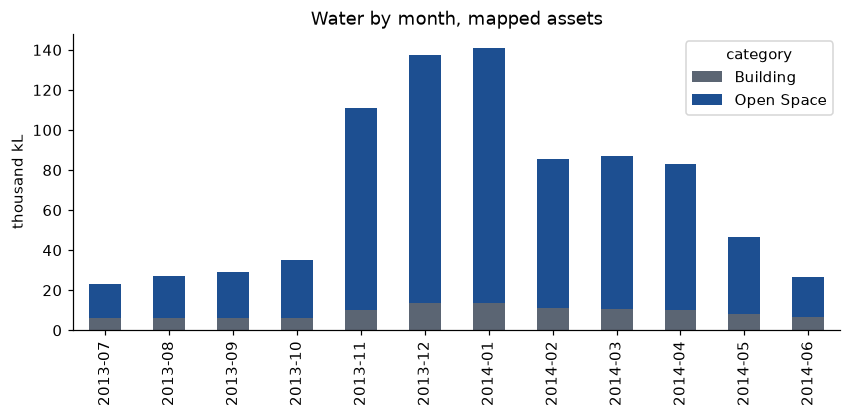

In [6]:
w = usage[usage.measure == 'Water'].merge(assets[['asset_name', 'category', 'water_days_billed']], on='asset_name')
by = w.groupby(['month', 'category']).amount.sum().unstack()
print((by / 1000).round(1))
osp = by['Open Space']
print('parks, January over July:', round(osp['2014-01'] / osp['2013-07'], 1))
full = w[(w.category == 'Open Space') & (w.water_days_billed == 365)].groupby('month').amount.sum()
print('parks billed every day of the year, January over July:', round(full['2014-01'] / full['2013-07'], 1))
ax = (by / 1000).plot(kind='bar', stacked=True, color=[MUTED, INK], figsize=(9, 3.5))
ax.set_ylabel('thousand kL'); ax.set_xlabel(''); ax.set_title('Water by month, mapped assets')
plt.show()

## Water per park, and two bills to query

The year's water divided by the council parcel each park was placed on gives a depth in millimetres. It is over the whole
parcel (paths, lawns and beds), not the irrigated area. Two stand out, and the bills explain why: Parliament Reserve's
water bills cover only part of the year, with a gap from November to February and then most of its year's water in three
months; Southbank Promenade is billed on several meters at once. Both are bills to query before anyone treats them as
watering rates.

In [7]:
parks = assets[(assets.category == 'Open Space') & assets.property_id.notna() & ~assets.asset_name.str.startswith('Lease')].set_index('asset_name')
depth = (year.Water.reindex(parks.index) / parks.area_m2 * 1000).round(0).sort_values(ascending=False)
print(pd.DataFrame({'mm': depth, 'days billed': parks.water_days_billed}).to_string())
print('median', depth.median())
bills = pd.read_csv(f'{DATA}/usage/bills.csv')
print(bills[(bills.asset_name == 'Park - Parliament') & (bills.measure == 'Water')].to_string(index=False))

                                   mm  days billed
asset_name                                        
Garden - Carlton South          662.0        365.0
Garden - Fitzroy                203.0        365.0
Garden - Flagstaff              422.0        365.0
Garden - Queen Victoria         421.0        365.0
Garden - Treasury               491.0        365.0
Garden Alexandra                616.0        365.0
Park - Birrarung Marr           420.0        365.0
Park - Fawkner                  199.0        365.0
Park - JJ Holland                58.0        365.0
Park - Kings Domain             403.0        365.0
Park - Parliament              3710.0        211.0
Park - Princes Park             211.0        365.0
Park - Royal Park                 6.0        365.0
Park - Shrine                   615.0        365.0
Reserve - Darling Square        622.0        365.0
Reserve - Jolimont              649.0        365.0
Reserve - Lincoln Square        232.0        365.0
Reserve - Point Park           

## Electricity per square metre of floor

For buildings with their own footprint: the year's grid electricity over an estimated floor area, the footprint picked in
Plotlay times the floors above ground in the council's 2014 building census (CLUE). An estimate, so read it as a ranking
to start questions, not a rating. Two leases share a building with others and are not compared.

In [8]:
b = assets[assets.floor_m2_est.notna()].set_index('asset_name')
kwh = (year.Electricity.reindex(b.index) / b.floor_m2_est).dropna().round(1).sort_values(ascending=False)
shared = ['Library - City', 'Lease - 225 Bourke St - City Village']
print(kwh.to_string())
print('median of the rest:', kwh.drop(shared, errors='ignore').median())

asset_name
Recreation Centre - North Melbourne                  282.7
Administration - Council House 1                     147.6
Library - East Melbourne                             142.5
Library - North Melbourne                            133.6
Community Centre - Southbank                         114.5
Recreation Centre - City Baths                        97.4
Lease - 225 Bourke St - City Village                  93.2
Community Centre - Docklands Hub                      91.0
Administration - Melbourne Town Hall                  88.7
Administration - Council House 2                      86.3
Arts Centre - Nth Melb Town Hall                      63.4
Lease - Melbourne Town Hall                           57.9
Lease - Multicultural Hub                             53.0
Lease - Car Park Elgin Street                         28.6
Library - City                                        28.4
Administration - 602 Little Bourke Street Storage     28.2
Arts Centre - Meat Market                    

## The map, January 2014

Every mapped asset coloured by its water that month. Lines are boulevards; points are sites with no outline.

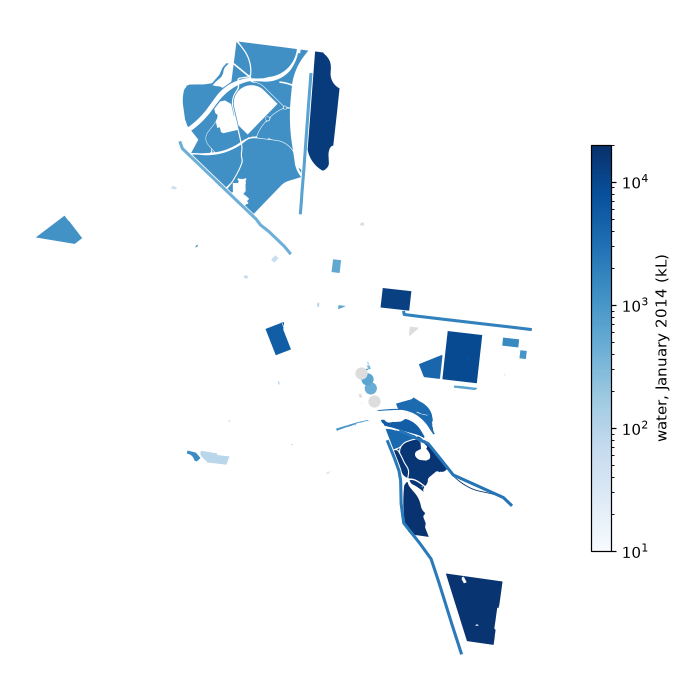

In [9]:
jan = usage[(usage.measure == 'Water') & (usage.month == '2014-01')].set_index('asset_name').amount
s = shapes.to_crs(7855).copy(); s['kl'] = s.key.map(jan)
ax = s.plot(column='kl', cmap='Blues', norm=plt.matplotlib.colors.LogNorm(10, 20000), legend=True, figsize=(8, 8), missing_kwds={'color': '#ddd'}, linewidth=2,
            legend_kwds={'label': 'water, January 2014 (kL)', 'shrink': .6})
ax.set_axis_off(); plt.show()

## Rows with no shape still count

Six network assets (street lighting, cameras, parking meters, signs, many small street reserves) have no single place, and
two reserves are not named in any council layer. They stay in the table: the totals above include them only where the
council's own bills are summed, not on the map. Street lighting alone is about a quarter of the council's electricity.

In [10]:
bills['start'] = pd.to_datetime(bills.billing_start); bills['end'] = pd.to_datetime(bills.billing_end)
fy0, fy1 = pd.Timestamp('2013-07-01'), pd.Timestamp('2014-06-30')
days = (bills.end - bills.start).dt.days + 1
inside = ((bills.end.clip(upper=fy1) - bills.start.clip(lower=fy0)).dt.days + 1).clip(lower=0)
bills['fy'] = bills.amount * inside / days
net = bills[bills.asset_name.isin(left.asset_name)].groupby(['asset_name', 'measure']).fy.sum().unstack().fillna(0).round(0)
print(net.to_string())

measure                                Electricity    Water
asset_name                                                 
Information - Parking Signage Network     163467.0      0.0
Parking Meters - Melbourne Network        107627.0      0.0
Reserve - Buncle Street                        0.0   4901.0
Security Cameras - Melbourne Network      159825.0      0.0
Street Lighting - Docklands Network      1972690.0      0.0
Street Lighting - Melbourne Network      1674243.0      0.0
Street Reserve - Investigator Drive            0.0   5697.0
Street Reserve - Miscellaneous               678.0  62048.0
